# **Оценка стоимости аренды жилья Airbnb в Нью-Йорке**

In [1]:
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения
import json
pd.set_option('display.max_columns', 100)
%matplotlib inline

# 0. Описание задачи

Данные — выгрузка объявлений Airbnb по Нью-Йорку с сайта [Inside Airbnb](https://insideairbnb.com/) (от 14.09.2026). Каждая строка — одно объявление: тип и размер жилья, район и координаты, сведения о хозяине, условия аренды, отзывы и рейтинги.

Нужно по характеристикам объявления предсказать **цену за ночь** `price` (в долларах). Это задача **регрессии**, как на лекции с квартирами Нижнего Новгорода. Такая модель могла бы, например, подсказывать хозяину «рыночную» цену для нового объявления.

Сначала мы взяли популярный на Kaggle датасет *Airbnb Open Data*, но цена в нём, похоже, сгенерирована случайно (равномерно от \$50 до \$1200 и ни от чего не зависит), поэтому перешли на данные Inside Airbnb.

Качество измеряем с помощью RMSE и $R^2$ на обучающей и тестовой выборках.

# 1. Загружаем данные

Файл `nyc_listings.csv.gz` скачан с [Inside Airbnb](https://insideairbnb.com/get-the-data/), `pandas` читает сжатый csv сам:

In [2]:
data_raw = pd.read_csv('nyc_listings.csv.gz', low_memory=False)
data_raw.shape

(29918, 90)

In [3]:
data_raw.head(3).T

,0,1,2
id,1352055619826961511,1215930899551057941,1203866180302079266
listing_url,https://www.airbnb.com/rooms/1352055619826961511,https://www.airbnb.com/rooms/1215930899551057941,https://www.airbnb.com/rooms/1203866180302079266
scrape_id,20260914002229,20260914002229,20260914002229
last_scraped,2026-09-14,2026-09-14,2026-09-15
source,NaN,NaN,NaN
...,...,...,...
calculated_host_listings_count,1,1,2
calculated_host_listings_count_entire_homes,1,0,0
calculated_host_listings_count_private_rooms,0,1,2
calculated_host_listings_count_shared_rooms,0,0,0


In [4]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 29918 entries, 0 to 29917
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29918 non-null  int64  
 1   listing_url                                   29918 non-null  str    
 2   scrape_id                                     29918 non-null  int64  
 3   last_scraped                                  29918 non-null  str    
 4   source                                        8906 non-null   str    
 5   name                                          29917 non-null  str    
 6   description                                   29772 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29918 non-null  str    
 9   host_id                                       29918 non-null  int64  
 1

Столбцов 90, основные группы:
- расположение: `neighbourhood_group_cleansed` (боро: Manhattan, Brooklyn, …), `neighbourhood_cleansed` (микрорайон), `latitude`, `longitude`;
- жильё: `room_type`, `property_type`, `accommodates` (вместимость), `bedrooms`, `beds`, `bathrooms_text`, `amenities` (список удобств);
- условия аренды: `minimum_nights`, `maximum_nights`, `availability_*` (сколько дней свободно), `license` (регистрационный номер);
- хозяин: `host_is_superhost`, `host_listings_count`, стаж на Airbnb и т.д.;
- отзывы: `number_of_reviews`, `reviews_per_month`, `review_scores_*` (оценки от 1 до 5);
- тексты (`name`, `description`) и служебные столбцы (id, ссылки, дата выгрузки).

Целевой признак — `price`.

### Целевая переменная

Цена записана строкой вида `$164.55`, переведём её в число:

In [5]:
data_raw['price'].head()

0        NaN
1    $164.55
2        NaN
3        NaN
4        NaN
Name: price, dtype: str

In [6]:
data_raw['price'] = pd.to_numeric(data_raw['price'].str.replace(r'[$,]', '', regex=True))
data_raw['price'].describe()

count    19406.000000
mean       310.165607
std        574.094115
min         17.700000
25%        103.682500
50%        182.445000
75%        337.000000
max      31537.820000
Name: price, dtype: float64

Медиана — \$182, среднее — \$310, а максимум — \$31 538 за ночь: распределение сильно скошено.

### Удаляем ненужные столбцы

В выгрузке 13 полностью пустых столбцов:

In [7]:
empty_columns = [c for c in data_raw.columns if data_raw[c].isna().all()]
len(empty_columns), empty_columns

(13,
 ['neighborhood_overview',
  'host_since',
  'host_response_time',
  'host_response_rate',
  'host_acceptance_rate',
  'host_thumbnail_url',
  'host_neighbourhood',
  'host_total_listings_count',
  'host_verifications',
  'neighbourhood',
  'bathrooms',
  'calendar_updated',
  'instant_bookable'])

In [8]:
technical_columns = ['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'picture_url',
                     'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_picture_url',
                     'calendar_last_scraped']
data_raw[technical_columns].nunique()

id                       29918
listing_url              29918
scrape_id                    1
last_scraped                 2
source                       1
picture_url              29297
host_id                  16148
host_url                 16148
host_profile_id          16148
host_profile_url         16148
host_picture_url         15703
calendar_last_scraped        2
dtype: int64

Технические столбцы (id, ссылки, дата выгрузки) для предсказания не нужны. Кроме того, есть столбцы, через которые «утекает» сама цена:

In [9]:
leak_columns = ['price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price',
                'price_quote_price_per_night', 'price_quote_raw', 'estimated_revenue_l365d']
data_raw[['price', 'price_quote_price_per_night', 'price_quote_total_price', 'estimated_revenue_l365d']].corr()

,price,price_quote_price_per_night,price_quote_total_price,estimated_revenue_l365d
price,1.000000,1.000000,0.633046,0.204099
price_quote_price_per_night,1.000000,1.000000,0.633046,0.204091
price_quote_total_price,0.633046,0.633046,1.000000,-0.084558
estimated_revenue_l365d,0.204099,0.204091,-0.084558,1.000000


`price_quote_price_per_night` совпадает с ценой (корреляция 1), `price_quote_total_price` — цена конкретного бронирования, а `estimated_revenue_l365d` — оценка годового дохода, т.е. цена × число занятых ночей. У нового объявления этих значений не будет, поэтому удаляем их.

In [10]:
data = data_raw.drop(empty_columns + technical_columns + leak_columns, axis=1)
data['price'].isna().sum(), data['price'].isna().mean()

(np.int64(10512), np.float64(0.35136038505247674))

У 10 512 объявлений (35 %) цена не указана — учиться на них нельзя, удаляем.

In [11]:
data = data[data['price'].notna()]
data.shape

(19406, 59)

Основные характеристики датасета (из задания 1):

| Характеристика | Значение |
|---|---|
| Название датасета | Inside Airbnb — New York City listings (14.09.2026) |
| N (число объектов) | 19 406 (в исходном файле 29 918, у 10 512 нет цены) |
| d (число признаков) | 58 (в исходном файле 89) |
| K (число классов) | — (регрессия, целевая переменная `price`) |
| Пропущенные значения, % | 7,2 % ячеек (хотя бы один пропуск — в 91 % строк, в основном из-за `license`: 77 %) |
| Несбалансированные классы | нет (регрессия); тип жилья `room_type`: 52 / 45 / 2 / 1 |
| Выбросы, % | ≈ 8,5 % (по цене, правило 1.5·IQR); 2,1 % по квантилям 0.005 / 0.995 |
| Числовые признаки | 40 |
| Категориальные признаки | 11 |
| Текстовые признаки | 3 (`name`, `description`, `host_about`) |
| Признаки других типов | 4: даты (`first_review`, `last_review`), список (`amenities`), имя (`host_name`) |

# 2. Разбиваем данные на обучающую и тестовую выборки

Делим данные в пропорции 75 / 25. Дальше всё (выбросы, заполнение пропусков, масштабирование, выбор $k$) считаем только по обучающей выборке.

In [12]:
X = data.drop('price', axis=1)
y = data['price']

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape

N_train, N_test

(14554, 4852)

# 3. Визуализация и основные характеристики

Смотрим на обучающую выборку. Для удобства добавим к признакам цену и её логарифм:

In [14]:
train = X_train.join(y_train)
train['log_price'] = np.log(train['price'])

### Целевая переменная

In [15]:
y_train.describe()

count    14554.000000
mean       313.511327
std        610.880784
min         21.060000
25%        102.320000
50%        180.510000
75%        334.962500
max      31537.820000
Name: price, dtype: float64

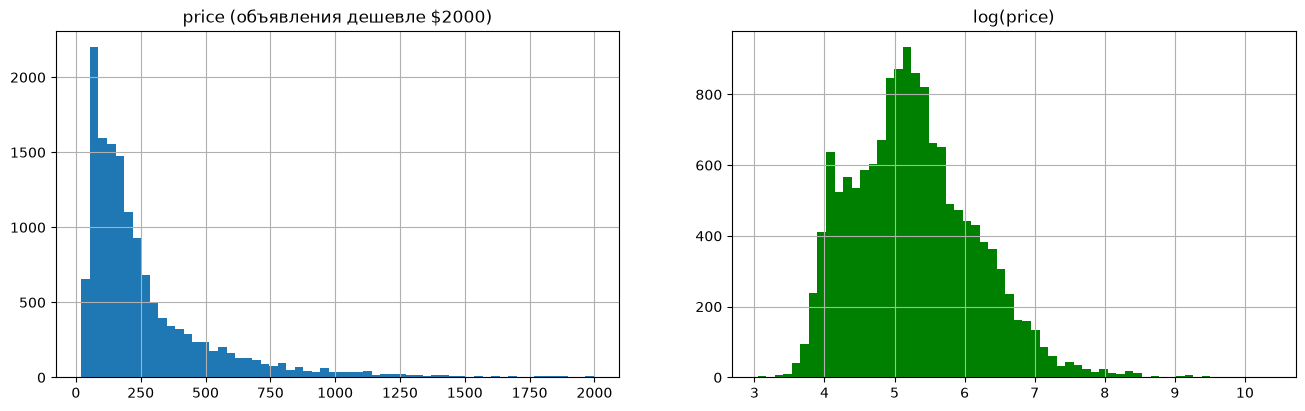

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(y_train[y_train < 2000], bins=60)
axes[0].set_title('price (объявления дешевле $2000)')
axes[1].hist(np.log(y_train), bins=60, color='g')
axes[1].set_title('log(price)')
for ax in axes:
    ax.grid()
pass

Цена сильно скошена вправо: стандартное отклонение (\$611) почти вдвое больше среднего (\$314), есть длинный хвост дорогих объявлений. Логарифм цены распределён почти симметрично, поэтому предсказывать будем $\log(\text{price})$ (см. п. 7).

### Числовые признаки

In [17]:
key_num = ['accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'availability_365',
           'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'host_listings_count']
train[key_num].describe().round(2)

,accommodates,bedrooms,beds,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,host_listings_count
count,14554.00,14533.00,13872.00,14550.00,1.455000e+04,14554.00,14554.00,10768.00,10768.00,14554.00
mean,2.94,1.29,1.72,23.71,1.771656e+06,252.90,41.64,1.22,4.72,150.38
std,2.10,0.91,1.26,18.14,6.164880e+07,102.52,98.45,3.17,0.48,742.37
min,1.00,0.00,1.00,1.00,1.000000e+00,0.00,0.00,0.01,1.00,1.00
25%,2.00,1.00,1.00,4.00,2.700000e+02,178.00,0.00,0.15,4.65,1.00
50%,2.00,1.00,1.00,30.00,3.650000e+02,274.00,6.00,0.43,4.85,3.00
75%,4.00,2.00,2.00,30.00,1.125000e+03,344.00,44.00,1.38,5.00,17.00
max,16.00,19.00,42.00,365.00,2.147484e+09,365.00,4894.00,146.87,5.00,5711.00


- Обычно жильё на 2–4 человека с одной спальней, но есть объявления с 19 спальнями и 42 кроватями — похоже на выбросы.
- Медиана минимального срока аренды — 30 ночей (об этом ниже). `maximum_nights` доходит до 2 147 483 647 — видимо, так записан «бесконечный» срок.
- У четверти объявлений нет отзывов, а рейтинги почти у всех высокие (медиана 4,85 из 5).
- У некоторых хозяев тысячи объявлений — это отели и управляющие компании.

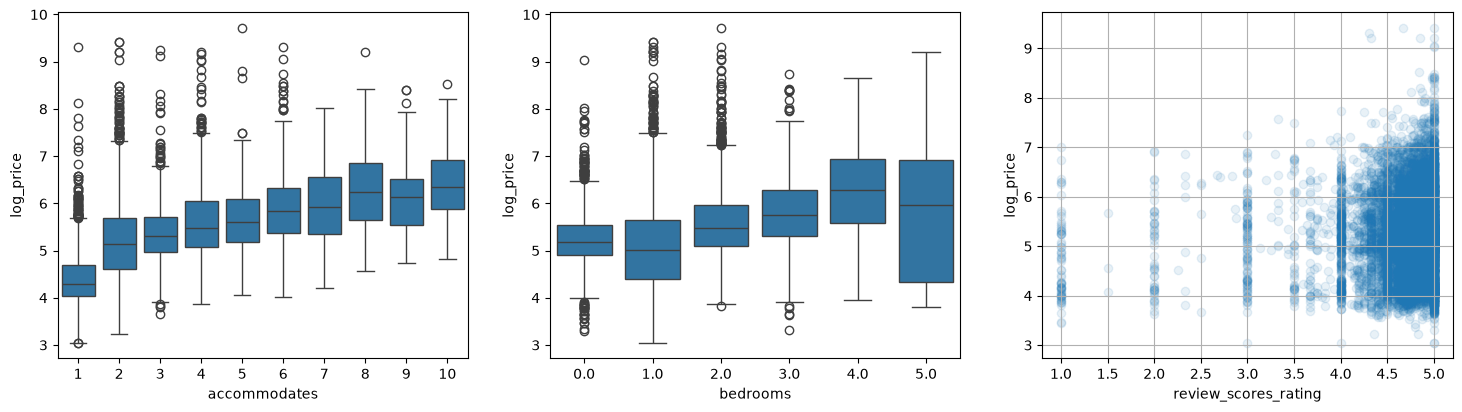

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(x='accommodates', y='log_price', data=train[train['accommodates'] <= 10], ax=axes[0])
sns.boxplot(x='bedrooms', y='log_price', data=train[train['bedrooms'] <= 5], ax=axes[1])
axes[2].scatter(train['review_scores_rating'], train['log_price'], alpha=0.1)
axes[2].set_xlabel('review_scores_rating')
axes[2].set_ylabel('log_price')
axes[2].grid()
pass

Цена растёт с вместимостью и числом спален, хотя разброс внутри групп большой. С рейтингом цена почти не связана: высокие оценки и у дешёвых, и у дорогих объявлений.

### Категориальные признаки

In [19]:
train.select_dtypes(exclude='number').describe().T

,count,unique,top,freq
name,14554,14130,45 West 81st Studio,13
description,14498,11558,You'll have a great time at this comfortable p...,123
host_name,14554,4285,Jeniffer,241
host_location,10283,310,"New York, NY",7929
host_about,8483,4164,"Great working experience in hospitality, Actua...",213
host_is_superhost,14554,2,f,10441
host_has_profile_pic,14554,2,t,13935
host_identity_verified,14554,2,t,14310
neighbourhood_cleansed,14554,222,Midtown,1075
neighbourhood_group_cleansed,14554,5,Manhattan,6619


- `name`, `description` и `amenities` почти уникальны — это тексты и списки, а не категории.
- `host_name` для предсказания бесполезен, `host_location` записан по-разному («New York, NY», «New York, United States», …) — оба столбца удалим.
- `license` заполнен только у 3407 объявлений из 14 554 (см. ниже).
- Микрорайонов 222, типов объектов 56, но большинство значений встречается редко.

In [20]:
train.groupby('room_type')['price'].agg(['count', 'median']).sort_values('count', ascending=False)

,count,median
room_type,,
Entire home/apt,7601,215.63
Private room,6513,113.95
Hotel room,319,649.94
Shared room,121,87.67


In [21]:
train.groupby('neighbourhood_group_cleansed')['price'].agg(['count', 'median']).sort_values('count', ascending=False)

,count,median
neighbourhood_group_cleansed,,
Manhattan,6619,262.730
Brooklyn,4722,153.845
Queens,2417,126.650
Bronx,574,103.790
Staten Island,222,102.970


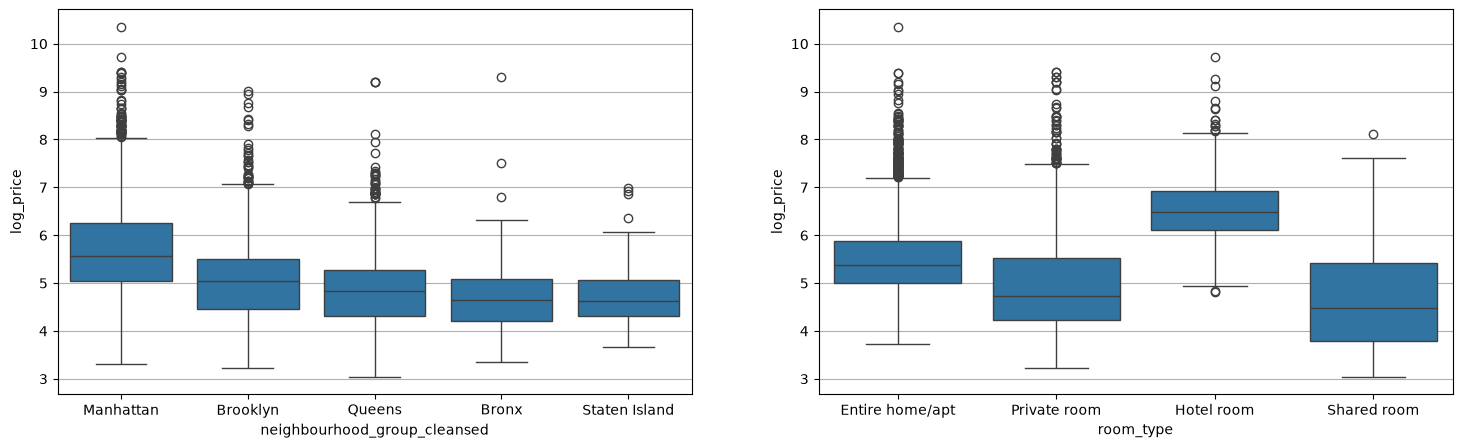

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.boxplot(x='neighbourhood_group_cleansed', y='log_price', data=train,
            order=train['neighbourhood_group_cleansed'].value_counts().index, ax=axes[0])
sns.boxplot(x='room_type', y='log_price', data=train, order=train['room_type'].value_counts().index, ax=axes[1])
for ax in axes:
    ax.grid(axis='y')
pass

- Квартира целиком стоит в медиане \$216, отдельная комната — \$114, номер в отеле — \$650. Номеров в отелях и общих комнат мало (2 % и меньше 1 %).
- Самый дорогой боро — Манхэттен (медиана \$263), дешевле всего — Бронкс и Статен-Айленд (около \$103).

### Минимальный срок аренды

С 2023 г. в Нью-Йорке сдавать жильё меньше чем на 30 дней можно только с регистрацией (номер записывается в поле `license`). Видно, что многие объявления поэтому помесячные:

In [23]:
train['minimum_nights'].value_counts().head(8)

minimum_nights
30.0    10345
1.0      2715
2.0       597
3.0       280
31.0      174
4.0        85
90.0       66
60.0       56
Name: count, dtype: int64

In [24]:
train.groupby(train['minimum_nights'] >= 30)['price'].agg(['count', 'median'])

,count,median
minimum_nights,,
False,3810,380.930
True,10744,145.425


In [25]:
pd.crosstab(train['license'].notna(), train['minimum_nights'] >= 30)

minimum_nights,False,True
license,,
False,461,10686
True,3349,58


У 74 % объявлений минимальный срок — от 30 ночей, и в пересчёте на ночь такое жильё заметно дешевле (медиана \$145 против \$381). Лицензия есть почти только у краткосрочных объявлений, так что пропуск в `license` — не потерянное значение, а признак помесячной аренды.

### Цена на карте

Как на лекции, нарисуем объявления по координатам, цвет — логарифм цены:

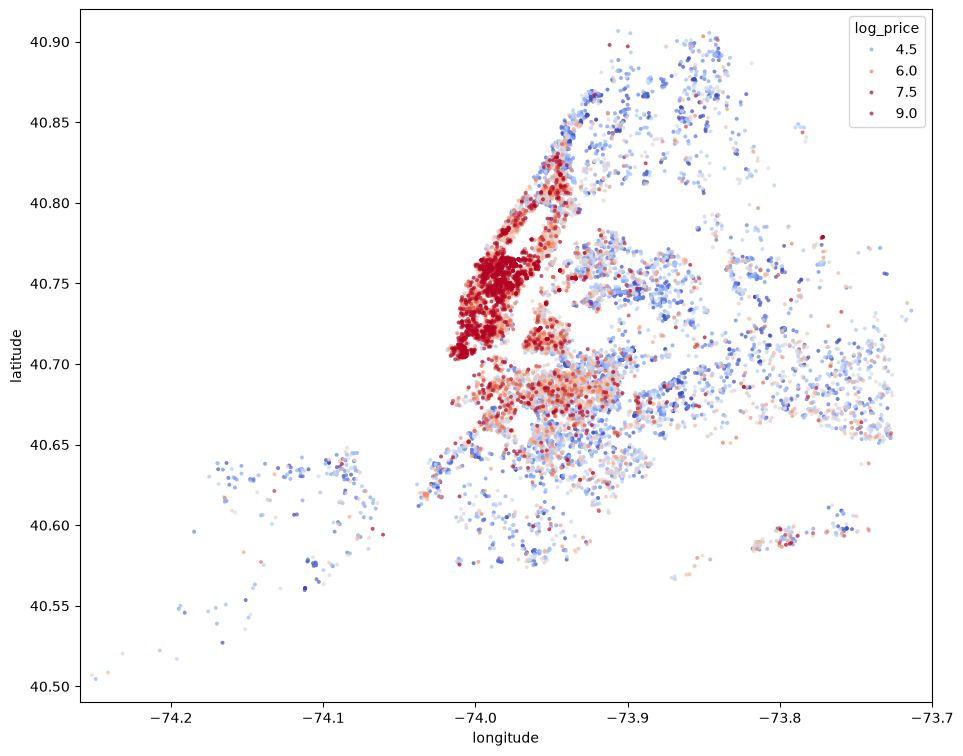

In [26]:
plt.figure(figsize=(11, 9))
sns.scatterplot(x='longitude', y='latitude', hue='log_price', hue_norm=(4, 6.5), data=train.sort_values('log_price'),
                palette='coolwarm', s=8, linewidth=0, alpha=0.7)
plt.xlim(-74.26, -73.70)
plt.ylim(40.49, 40.92)
pass

Самые дорогие объявления — в Манхэттене южнее Центрального парка и в соседних частях Бруклина, чем дальше от центра, тем дешевле. Поэтому в п. 6 добавим признак «расстояние до центра».

### Корреляционная матрица

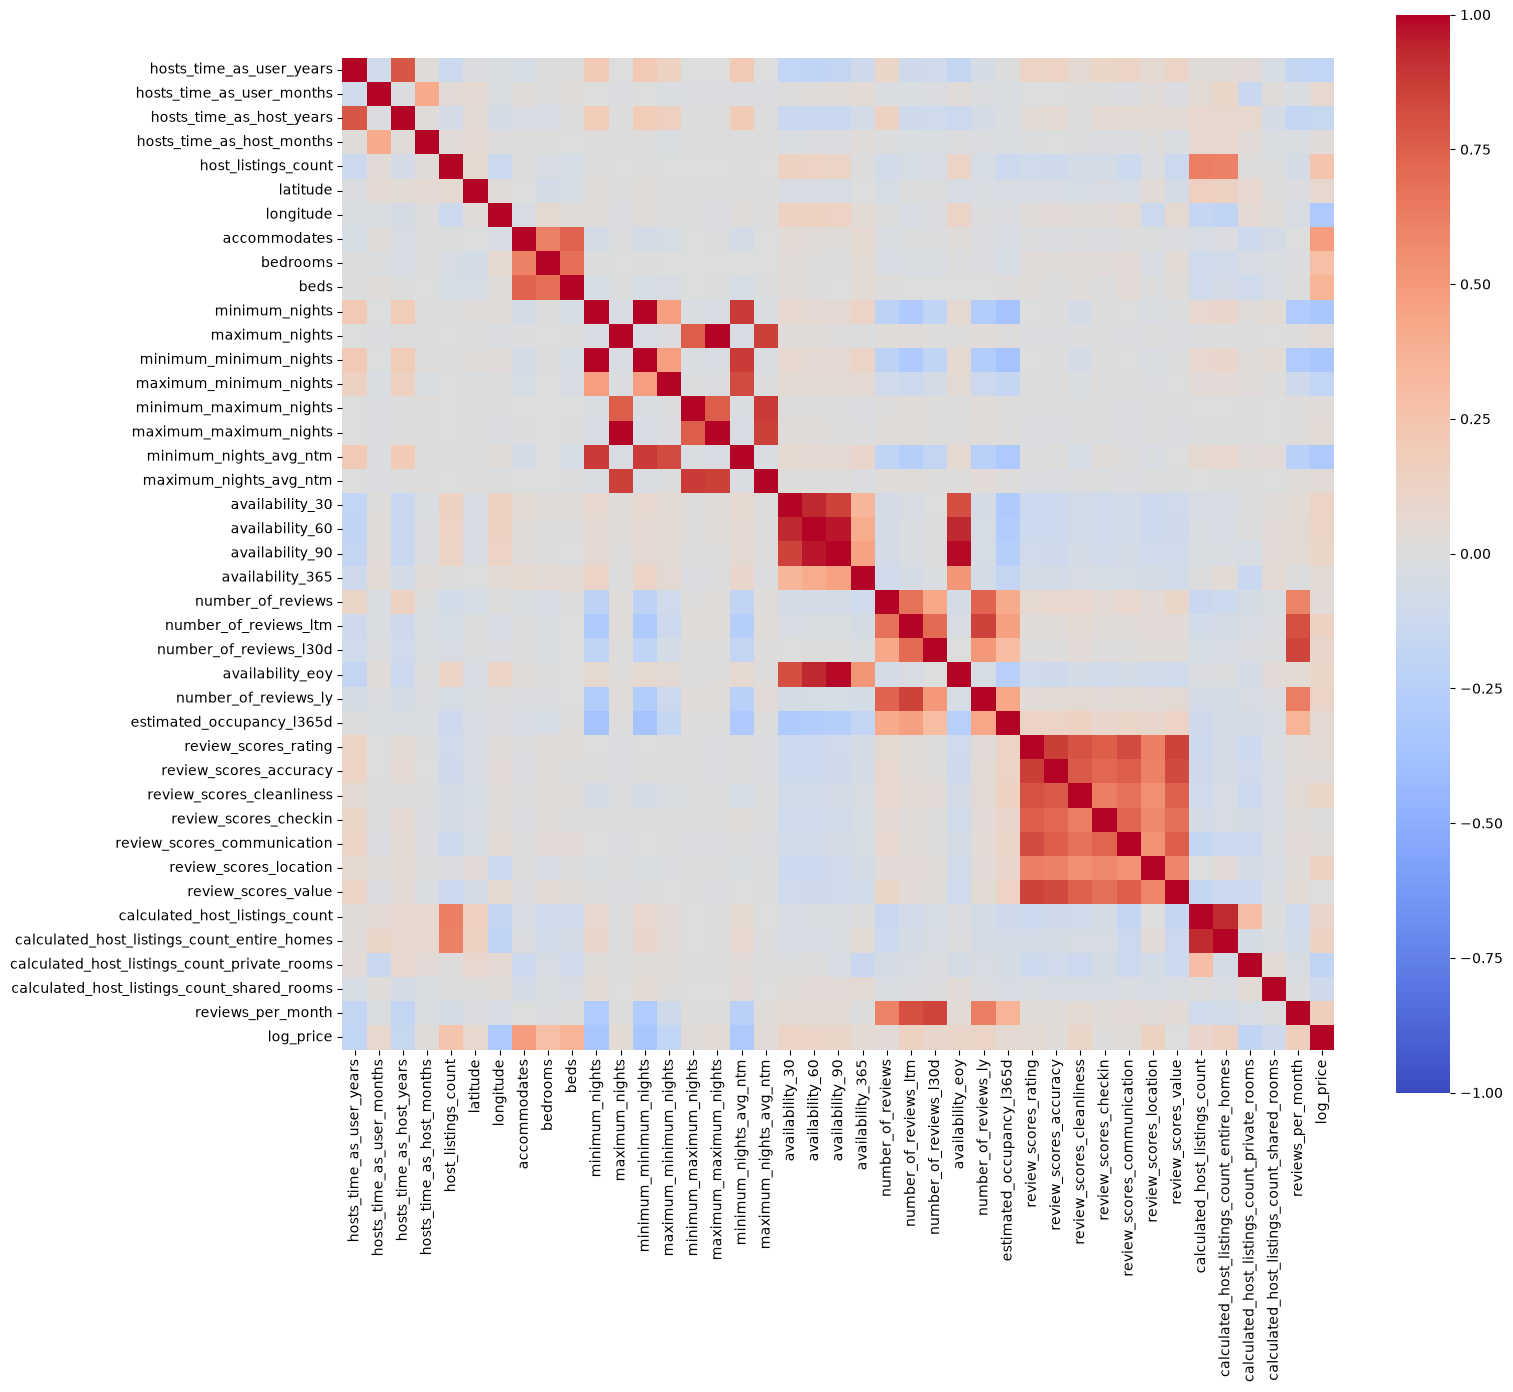

In [27]:
num_columns = list(train.select_dtypes('number').columns.drop(['price', 'log_price']))
corr_mat = train[num_columns + ['log_price']].corr()
plt.figure(figsize=(16, 14))
sns.heatmap(corr_mat, square=True, vmin=-1, vmax=1, cmap='coolwarm')
pass

In [28]:
corr_mat['log_price'].drop('log_price').sort_values()

minimum_minimum_nights                         -0.338481
minimum_nights                                 -0.338481
longitude                                      -0.309761
minimum_nights_avg_ntm                         -0.309144
calculated_host_listings_count_private_rooms   -0.193427
hosts_time_as_user_years                       -0.186626
maximum_minimum_nights                         -0.184256
hosts_time_as_host_years                       -0.149671
calculated_host_listings_count_shared_rooms    -0.106483
review_scores_value                            -0.000102
review_scores_checkin                           0.013778
review_scores_communication                     0.021731
review_scores_accuracy                          0.024713
minimum_maximum_nights                          0.027285
hosts_time_as_host_months                       0.031183
maximum_nights_avg_ntm                          0.032796
number_of_reviews                               0.035742
maximum_nights                 

- С ценой сильнее всего связаны вместимость `accommodates` (0,48), число кроватей и спален; отрицательно — минимальный срок аренды (−0,34) и долгота (−0,31: к востоку от Манхэттена дешевле).
- На матрице видны группы почти одинаковых признаков: варианты `minimum_nights` и `maximum_nights`, `availability_30/60/90`, оценки отзывов. Вернёмся к ним в п. 12.

# 4. Выбросы

In [29]:
outlier_columns = ['price', 'accommodates', 'bedrooms', 'beds', 'minimum_nights']
train[outlier_columns].quantile([0.005, .01, .05, .1, .5, .9, .95, .99, .995])

,price,accommodates,bedrooms,beds,minimum_nights
0.005,39.7300,1.0,0.0,1.0,1.0
0.010,43.4506,1.0,0.0,1.0,1.0
0.050,54.8890,1.0,0.0,1.0,1.0
0.100,63.2700,1.0,1.0,1.0,1.0
0.500,180.5100,2.0,1.0,1.0,30.0
0.900,623.1190,6.0,2.0,3.0,30.0
0.950,888.7075,7.0,3.0,4.0,30.0
0.990,2100.2550,12.0,4.0,6.0,60.0
0.995,3388.2056,15.0,5.0,8.0,90.0


99 % цен лежат между \$40 и \$3388, а максимум — \$31 538. Есть и объявления с 19 спальнями и 42 кроватями. Как на лекции, удалим из обучающей выборки объекты, у которых хотя бы одно из этих значений выходит за квантили $0.005$ и $0.995$:

In [30]:
q_low  = train[outlier_columns].quantile(0.005)
q_high = train[outlier_columns].quantile(0.995)

rows_to_drop = train[((train[outlier_columns] < q_low) | (train[outlier_columns] > q_high)).any(axis=1)].index
len(rows_to_drop), len(rows_to_drop) / N_train

(294, 0.020200632128624434)

In [31]:
X_train = X_train.drop(rows_to_drop)
y_train = y_train.drop(rows_to_drop)
N_train, _ = X_train.shape
N_train

14260

Удалено 294 объекта (2 %). Из тестовой выборки ничего не удаляем: модель должна работать на любых новых объявлениях.

# 5. Пропущенные значения

In [32]:
X_train.isna().sum()[X_train.isna().sum() > 0].sort_values(ascending=False)

license                        10937
host_about                      5932
host_location                   4154
review_scores_checkin           3644
review_scores_rating            3644
first_review                    3644
last_review                     3644
review_scores_cleanliness       3644
review_scores_value             3644
review_scores_location          3644
reviews_per_month               3644
review_scores_communication     3644
review_scores_accuracy          3644
beds                             662
bathrooms_text                    58
description                       56
bedrooms                          14
minimum_nights                     4
maximum_nights                     4
minimum_minimum_nights             4
minimum_maximum_nights             4
maximum_minimum_nights             4
maximum_maximum_nights             4
has_availability                   1
dtype: int64

Больше всего пропусков в `license` (77 %) — как мы видели, это объявления без лицензии. `host_about` и `host_location` хозяева просто не заполнили. Оценки, `reviews_per_month` и даты отзывов пропущены у 3644 объявлений — похоже, это объявления без отзывов. Проверим:

In [33]:
review_columns = [c for c in X_train.columns if c.startswith('review_scores_')] + ['reviews_per_month']
pd.crosstab(X_train['number_of_reviews'] == 0, X_train[review_columns].isna().any(axis=1))

col_0,False,True
number_of_reviews,,
False,10616,0
True,0,3644


Так и есть. Поэтому добавим признак `HasReviews` (есть ли отзывы), `reviews_per_month` у объявлений без отзывов заполним нулём, а остальные пропуски в числовых признаках — медианой по обучающей выборке.

In [34]:
X_train['HasReviews'] = (X_train['number_of_reviews'] > 0).astype(int)
X_test['HasReviews']  = (X_test['number_of_reviews'] > 0).astype(int)
X_train['reviews_per_month'] = X_train['reviews_per_month'].fillna(0)
X_test['reviews_per_month']  = X_test['reviews_per_month'].fillna(0)

In [35]:
from sklearn.impute import SimpleImputer
num_raw_columns = X_train.select_dtypes('number').columns
imp_num = SimpleImputer(missing_values=np.nan, strategy='median')
imp_num.fit(X_train[num_raw_columns])
X_train[num_raw_columns] = imp_num.transform(X_train[num_raw_columns])
X_test[num_raw_columns]  = imp_num.transform(X_test[num_raw_columns])

In [36]:
X_train.isna().sum()[X_train.isna().sum() > 0]

description            56
host_location        4154
host_about           5932
bathrooms_text         58
has_availability        1
first_review         3644
last_review          3644
license             10937
dtype: int64

Остались пропуски только в нечисловых столбцах — их мы в п. 6 либо удалим, либо преобразуем.

# 6. Категориальные и другие нечисловые признаки

Что делаем:
- `t`/`f` → 1/0;
- `license` → `HasLicense` (есть лицензия или нет);
- `bathrooms_text` («1 bath», «1 shared bath», …) → число ванных `Baths` и признак общей ванной `SharedBath`;
- `amenities` → число удобств `NAmenities`;
- по координатам считаем расстояние до Таймс-сквер `DistCenter`;
- тексты, даты отзывов, имя и местоположение хозяина удаляем;
- `room_type`, `property_type`, боро и микрорайон бинаризуем.

In [37]:
X_train['bathrooms_text'].value_counts().head(10)

bathrooms_text
1 bath              6422
1 shared bath       2700
1 private bath      2469
2 baths             1021
2 shared baths       424
1.5 baths            367
1.5 shared baths     248
2.5 baths            131
3 baths              116
0 shared baths        82
Name: count, dtype: int64

In [38]:
center_lat, center_lng = 40.758, -73.9855   # Таймс-сквер

def make_features(D):
    D = D.copy()
    D['HasLicense'] = D['license'].notna().astype(int)
    D['NAmenities'] = D['amenities'].apply(lambda s: len(json.loads(s)))
    # '1.5 shared baths' -> 1.5 и признак общей ванной
    bath = D['bathrooms_text'].fillna('').str.lower()
    D['Baths'] = pd.to_numeric(bath.str.extract(r'(\d+\.?\d*)')[0], errors='coerce')
    D.loc[bath.str.contains('half'), 'Baths'] = 0.5
    D['Baths'] = D['Baths'].fillna(1)
    D['SharedBath'] = bath.str.contains('shared').astype(int)
    # расстояние до центра (в градусах)
    D['DistCenter'] = np.sqrt((D['latitude'] - center_lat)**2 + (D['longitude'] - center_lng)**2)
    for c in ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'has_availability']:
        D[c] = (D[c] == 't').astype(int)
    return D.drop(['name', 'description', 'host_about', 'host_name', 'host_location', 'amenities', 'license',
                   'bathrooms_text', 'first_review', 'last_review',
                   'hosts_time_as_host_months', 'hosts_time_as_user_months'], axis=1)

X_train = make_features(X_train)
X_test  = make_features(X_test)
X_train.shape, X_test.shape

((14260, 52), (4852, 52))

In [39]:
X_train[['HasLicense', 'NAmenities', 'Baths', 'SharedBath', 'DistCenter']].corrwith(np.log(y_train))

HasLicense    0.407461
NAmenities    0.174954
Baths         0.156890
SharedBath   -0.507631
DistCenter   -0.417426
dtype: float64

Сильнее всего с ценой связаны общая ванная `SharedBath` (−0,51: это комнаты и хостелы), расстояние до центра `DistCenter` (−0,42, сильнее, чем широта и долгота по отдельности) и наличие лицензии `HasLicense` (0,41, т.е. краткосрочная аренда).

Номинальные признаки бинаризуем с помощью `OneHotEncoder`. У микрорайона 221 значение, у типа объекта — 55, поэтому значения, которые встречаются в обучающей выборке реже 100 раз, объединяем в одну категорию (`min_frequency=100`).

In [40]:
from sklearn.preprocessing import OneHotEncoder
cat_columns = ['room_type', 'property_type', 'neighbourhood_group_cleansed', 'neighbourhood_cleansed']
enc = OneHotEncoder(sparse_output=False, min_frequency=100, handle_unknown='infrequent_if_exist')
enc.fit(X_train[cat_columns])

def one_hot(D):
    dummies = pd.DataFrame(enc.transform(D[cat_columns]), columns=enc.get_feature_names_out(), index=D.index)
    return pd.concat((D.drop(cat_columns, axis=1), dummies), axis=1)

X_train = one_hot(X_train)
X_test  = one_hot(X_test)
X_train.shape, X_test.shape

((14260, 107), (4852, 107))

# 7. Нормализация

kNN считает расстояния между объектами, поэтому признаки нужно привести к одному масштабу — иначе всё решат признаки с большими значениями (`maximum_nights` до $2 \cdot 10^9$, число отзывов и т.п.). Стандартизируем все небинарные признаки (среднее и стандартное отклонение — по обучающей выборке), а dummy-признаки оставим 0/1.

In [41]:
binary_columns = [c for c in X_train.columns if X_train[c].nunique() <= 2]
num_features   = [c for c in X_train.columns if c not in binary_columns]

X_train_raw = X_train.copy()   # для сравнения ниже

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train[num_features])
X_train[num_features] = scaler.transform(X_train[num_features])
X_test[num_features]  = scaler.transform(X_test[num_features])
len(num_features), len(binary_columns)

(41, 66)

Цену тоже логарифмируем: у неё длинный хвост, и без логарифма модель «подстраивалась» бы под немногие очень дорогие объявления. К тому же ошибка в логарифмах относительная: ошибиться на \$50 для комнаты за \$80 хуже, чем для квартиры за \$800.

In [42]:
y_train_log = np.log(y_train)
y_test_log  = np.log(y_test)

Проверим, насколько нормализация важна для kNN (кросс-валидация на обучающей выборке, $k = 10$):

In [43]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

for name, X_ in [('без нормализации', X_train_raw), ('со стандартизацией', X_train)]:
    rmse = -cross_val_score(KNeighborsRegressor(n_neighbors=10), X_, y_train_log, cv=5,
                            scoring='neg_root_mean_squared_error').mean()
    print(name, round(rmse, 4))

без нормализации 0.6097


со стандартизацией 0.382


Без нормализации RMSE = 0,610, со стандартизацией — 0,382: разница заметная.

# 8. Регрессия ближайших соседей

Берём kNN, который разбирали на лекции. Для цен это естественный метод: цену объявления оцениваем по ценам похожих объявлений (того же типа, размера, в том же районе), и линейной зависимости он не предполагает. Минус — все признаки входят в расстояние с одинаковым весом.

Начнём с $k = 10$, модель обучаем на $\log(\text{price})$:

In [44]:
knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_train, y_train_log)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


# 9. Ошибки на обучающей и тестовой выборках, подбор $k$

Матриц рассогласования для регрессии нет, поэтому считаем RMSE и $R^2$ (по логарифму цены). Результаты моделей будем собирать в таблицу:

In [45]:
from sklearn.metrics import mean_squared_error, r2_score

results = pd.DataFrame(columns=['RMSE_train', 'RMSE_test', 'R2_train', 'R2_test'])

def evaluate(name, model, X_tr, X_te):
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    results.loc[name] = [mean_squared_error(y_train_log, p_tr)**.5, mean_squared_error(y_test_log, p_te)**.5,
                         r2_score(y_train_log, p_tr), r2_score(y_test_log, p_te)]

evaluate('kNN, k = 10', knn, X_train, X_test)
results.round(3)

,RMSE_train,RMSE_test,R2_train,R2_test
"kNN, k = 10",0.339,0.397,0.833,0.783


На тесте RMSE = 0,397 и $R^2 = 0,78$, т.е. модель объясняет 78 % разброса логарифма цены. На обучающей выборке ошибка меньше (0,339) — небольшое переобучение есть.

### Подбор числа соседей

Подбираем $k$ по 5-кратной кросс-валидации на обучающей выборке:

In [46]:
from sklearn.model_selection import GridSearchCV
k_arr = [1, 3, 5, 7, 10, 15, 20, 30, 50]
grid = GridSearchCV(KNeighborsRegressor(), param_grid={'n_neighbors': k_arr}, cv=5,
                    scoring='neg_root_mean_squared_error', return_train_score=True, n_jobs=-1)
grid.fit(X_train, y_train_log)

best_cv_rmse = -grid.best_score_
best_n_neighbors = grid.best_params_['n_neighbors']
print(best_cv_rmse, best_n_neighbors)

0.38195518166654835 10


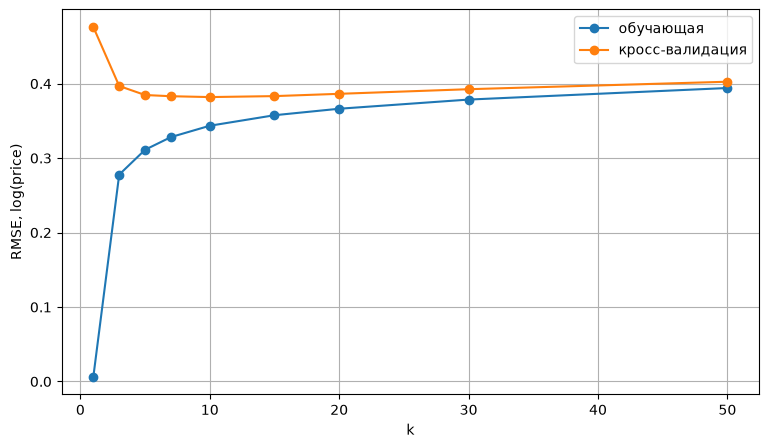

In [47]:
plt.figure(figsize=(9, 5))
plt.plot(k_arr, -grid.cv_results_['mean_train_score'], 'o-', label='обучающая')
plt.plot(k_arr, -grid.cv_results_['mean_test_score'], 'o-', label='кросс-валидация')
plt.xlabel('k')
plt.ylabel('RMSE, log(price)')
plt.legend()
plt.grid()
pass

- При $k = 1$ модель просто запоминает обучающую выборку: на ней ошибка почти нулевая, а на кросс-валидации — самая большая (переобучение).
- С ростом $k$ ошибка на обучающей выборке растёт, а на кросс-валидации сначала падает, а после $k \approx 10$ медленно растёт: усредняются слишком непохожие объявления.
- Оптимум — $k = 10$ (CV RMSE = 0,382), т.е. то значение, с которого мы начали. Между $k = 5$ и $k = 15$ кривая почти плоская.

In [48]:
knn = KNeighborsRegressor(n_neighbors=best_n_neighbors).fit(X_train, y_train_log)
evaluate(f'kNN, k = {best_n_neighbors}', knn, X_train, X_test)
results.round(3)

,RMSE_train,RMSE_test,R2_train,R2_test
"kNN, k = 10",0.339,0.397,0.833,0.783


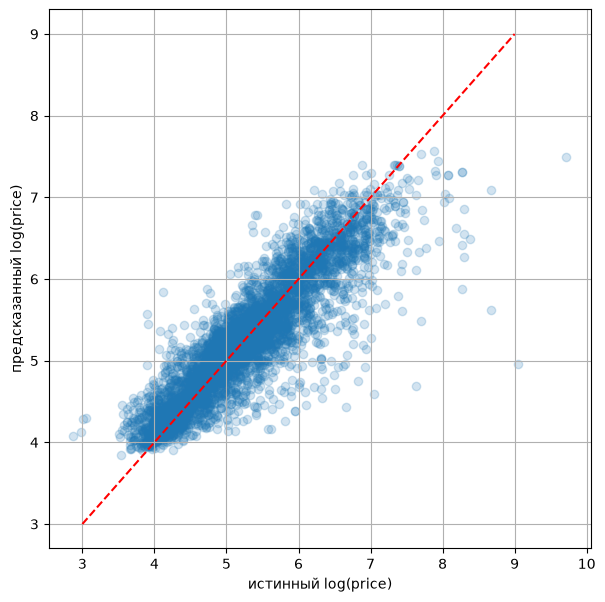

In [49]:
y_test_predict = knn.predict(X_test)
plt.figure(figsize=(7, 7))
plt.scatter(y_test_log, y_test_predict, alpha=0.2)
plt.plot([3, 9], [3, 9], 'r--')
plt.xlabel('истинный log(price)')
plt.ylabel('предсказанный log(price)')
plt.grid()
pass

Точки ложатся вдоль диагонали, но облако чуть положе неё: дорогие объявления модель недооценивает, а дешёвые — переоценивает. Это понятно: прогноз kNN — среднее цен соседей, и крайние значения сглаживаются.

# 10. Другие методы регрессии

Попробуем остальные методы из лекции: линейную регрессию, полносвязную нейронную сеть, случайный лес и градиентный бустинг.

In [50]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression().fit(X_train, y_train_log)
evaluate('Линейная регрессия', lr, X_train, X_test)

In [51]:
from sklearn.neural_network import MLPRegressor
mlp = MLPRegressor(hidden_layer_sizes=(20, 10), max_iter=1000, random_state=42).fit(X_train, y_train_log)
evaluate('Нейронная сеть', mlp, X_train, X_test)

In [52]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42).fit(X_train, y_train_log)
evaluate('Random Forest', rf, X_train, X_test)

In [53]:
from sklearn.ensemble import GradientBoostingRegressor
gbt = GradientBoostingRegressor(n_estimators=200, random_state=42).fit(X_train, y_train_log)
evaluate('Градиентный бустинг', gbt, X_train, X_test)

In [54]:
results.round(3)

,RMSE_train,RMSE_test,R2_train,R2_test
"kNN, k = 10",0.339,0.397,0.833,0.783
Линейная регрессия,0.388,0.420,0.781,0.756
Нейронная сеть,0.308,0.397,0.862,0.783
Random Forest,0.121,0.355,0.979,0.826
Градиентный бустинг,0.314,0.360,0.857,0.822


- Лучше всего работают случайный лес ($R^2 = 0,83$) и градиентный бустинг (0,82). Нейронная сеть на уровне kNN (0,78), линейная регрессия чуть хуже (0,76).
- Случайный лес сильно переобучается ($R^2$ на обучающей выборке 0,98), но на тесте всё равно лучший.
- Деревья сами выбирают важные признаки, а у kNN все 107 признаков входят в расстояние с одинаковым весом — видимо, поэтому kNN им уступает.

Значимость признаков по случайному лесу:

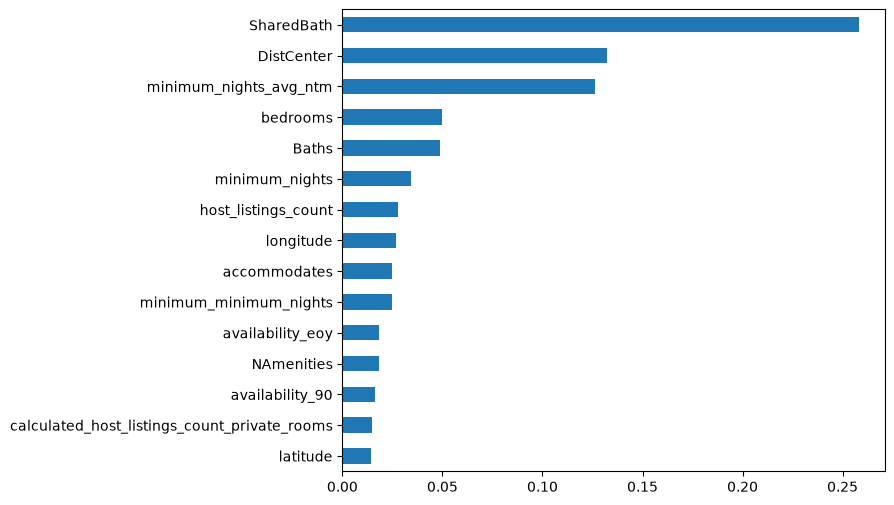

In [55]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importances.tail(15).plot.barh(figsize=(7, 6))
pass

Главные признаки — `SharedBath`, `DistCenter` и минимальный срок аренды (`minimum_nights_avg_ntm`, `minimum_nights`), дальше идут число спален и ванных. Три из пяти самых важных признаков мы построили сами в п. 6.

# 11. Несбалансированность

Классов в регрессии нет. Похожая проблема — длинный хвост цены: дорогих объявлений мало, но при обучении на самой цене они сильно влияют на квадратичную ошибку. С этим мы боролись логарифмированием (п. 7). Проверим, помогло ли оно: обучим kNN на цене без логарифма и сравним среднюю абсолютную ошибку в долларах на тестовой выборке.

In [56]:
knn_raw = KNeighborsRegressor(n_neighbors=best_n_neighbors).fit(X_train, y_train)
mae_log = np.mean(np.abs(np.exp(knn.predict(X_test)) - y_test))
mae_raw = np.mean(np.abs(knn_raw.predict(X_test) - y_test))
mae_log, mae_raw

(np.float64(97.26332750066315), np.float64(101.64980832646332))

С логарифмом средняя ошибка — \$97, без логарифма — \$102, т.е. логарифмирование немного помогло. Эффект небольшой: прогноз kNN — среднее цен соседей, он и так не выходит за пределы цен обучающей выборки.

# 12. Исключение коррелированных переменных

В п. 3 мы видели почти одинаковые признаки (например, `minimum_nights` и `minimum_minimum_nights`). Для kNN такая пара — один и тот же признак, учтённый в расстоянии дважды. Удалим по одному признаку из каждой пары с $|r| > 0.9$:

In [57]:
corr_proc = X_train.corr().abs()
upper = corr_proc.where(np.triu(np.ones(corr_proc.shape, dtype=bool), k=1))
drop_columns = [c for c in upper.columns if (upper[c] > 0.9).any()]
drop_columns

['minimum_minimum_nights',
 'maximum_maximum_nights',
 'maximum_nights_avg_ntm',
 'availability_60',
 'availability_90',
 'availability_eoy',
 'calculated_host_listings_count_entire_homes',
 'room_type_Private room']

In [58]:
X_train_dc = X_train.drop(drop_columns, axis=1)
X_test_dc  = X_test.drop(drop_columns, axis=1)

knn_dc = KNeighborsRegressor(n_neighbors=best_n_neighbors).fit(X_train_dc, y_train_log)
evaluate(f'kNN, k = {best_n_neighbors}, без коррелированных', knn_dc, X_train_dc, X_test_dc)

lr_dc = LinearRegression().fit(X_train_dc, y_train_log)
evaluate('Линейная регрессия, без коррелированных', lr_dc, X_train_dc, X_test_dc)

results.round(3)

,RMSE_train,RMSE_test,R2_train,R2_test
"kNN, k = 10",0.339,0.397,0.833,0.783
Линейная регрессия,0.388,0.420,0.781,0.756
Нейронная сеть,0.308,0.397,0.862,0.783
Random Forest,0.121,0.355,0.979,0.826
Градиентный бустинг,0.314,0.360,0.857,0.822
"kNN, k = 10, без коррелированных",0.340,0.398,0.831,0.781
"Линейная регрессия, без коррелированных",0.389,0.422,0.780,0.754


Удалили 8 признаков (дубли сроков аренды, `availability_60/90/eoy` и др.). Качество почти не изменилось: у kNN RMSE на тесте 0,397 → 0,398, у линейной регрессии 0,420 → 0,422. Видимо, при сотне признаков несколько дублей погоды не делают, так что выигрыша от удаления нет.

# 13. Выводы

In [59]:
results.sort_values('RMSE_test').round(3)

,RMSE_train,RMSE_test,R2_train,R2_test
Random Forest,0.121,0.355,0.979,0.826
Градиентный бустинг,0.314,0.360,0.857,0.822
"kNN, k = 10",0.339,0.397,0.833,0.783
Нейронная сеть,0.308,0.397,0.862,0.783
"kNN, k = 10, без коррелированных",0.340,0.398,0.831,0.781
Линейная регрессия,0.388,0.420,0.781,0.756
"Линейная регрессия, без коррелированных",0.389,0.422,0.780,0.754


- Задача — по объявлению Airbnb в Нью-Йорке предсказать цену за ночь (регрессия). После удаления пустых, технических и «утекающих» столбцов и объявлений без цены осталось 19 406 объектов.
- Цена сильно скошена, поэтому предсказывали её логарифм. Выбросы (2 % обучающей выборки) удалили по квантилям 0.005 / 0.995.
- Пропуски в основном осмысленные: нет лицензии — значит, аренда помесячная; нет оценок — значит, нет отзывов.
- Сильнее всего цену определяют тип жилья (общая ванная, комната или квартира целиком), расстояние до центра и срок аренды.
- Для kNN нормализация обязательна (CV RMSE 0,610 → 0,382). Оптимальное $k = 10$, на тесте $R^2 = 0,78$.
- Лучшие модели — случайный лес и градиентный бустинг ($R^2 \approx 0,82$–$0,83$). Удаление коррелированных признаков качество не улучшило.
- Улучшить модель, наверное, можно за счёт текстов объявлений и списка удобств, которые мы использовали лишь частично.